# Final report figures — Figures 1–16

This notebook reproduces **all and only the sixteen figures used in the current DATA3001 final report**. Each report figure is immediately followed by the code that loads the submitted data, recreates the visual, displays it inline and saves its PNG under the matching `final_submission/figures/report/RQ1/`, `RQ2/` or `RQ3/` folder.

The notebook does not retrain the forecasting models. It rebuilds report visuals from the frozen processed data and saved evaluation outputs included in `final_submission`.


## Shared setup


In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, TwoSlopeNorm
import xarray as xr


def locate_submission_root():
    start = Path.cwd().resolve()
    for base in [start, *start.parents]:
        if (base / "RQ1").is_dir() and (base / "RQ2").is_dir() and (base / "RQ3").is_dir():
            return base
        candidate = base / "final_submission"
        if (candidate / "RQ1").is_dir() and (candidate / "RQ2").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate final_submission.")


SUBMISSION = locate_submission_root()
RQ1_OUTPUT = SUBMISSION / "output" / "rq1"
RQ2 = SUBMISSION / "RQ2"
RQ3_OUTPUT = SUBMISSION / "RQ3" / "optimised_fnn" / "output"
REPORT_FIGURE_DIR = SUBMISSION / "figures" / "report"
LAND_GEOJSON = SUBMISSION / "00_shared" / "assets" / "ne_50m_land.geojson"
for rq in ("RQ1", "RQ2", "RQ3"):
    (REPORT_FIGURE_DIR / rq).mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 250,
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "legend.fontsize": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def finish_figure(fig, filename):
    number = int(filename[6:8])
    rq = "RQ1" if number <= 6 else "RQ2" if number <= 12 else "RQ3"
    path = REPORT_FIGURE_DIR / rq / filename
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    plt.show()
    return path


def draw_land(ax):
    """Draw the bundled Natural Earth land and island polygons."""
    with LAND_GEOJSON.open("r", encoding="utf-8") as handle:
        features = json.load(handle)["features"]

    for feature in features:
        geometry = feature.get("geometry") or {}
        coordinates = geometry.get("coordinates", [])
        if geometry.get("type") == "Polygon":
            polygons = [coordinates]
        elif geometry.get("type") == "MultiPolygon":
            polygons = coordinates
        else:
            continue
        for polygon in polygons:
            if not polygon:
                continue
            exterior = polygon[0]
            xs = [point[0] for point in exterior]
            ys = [point[1] for point in exterior]
            ax.fill(
                xs, ys, facecolor="#e4e1da", edgecolor="#59636e",
                linewidth=0.55, zorder=0,
            )


## Data and experimental design


### Figure 1 — Region A observation density and continuous-segment lengths

Region A hourly observation density in 0.25° × 0.25° cells and continuous-segment lengths. Of 2,058 segments, 939 contain the 96 observations needed for one complete forecast case.


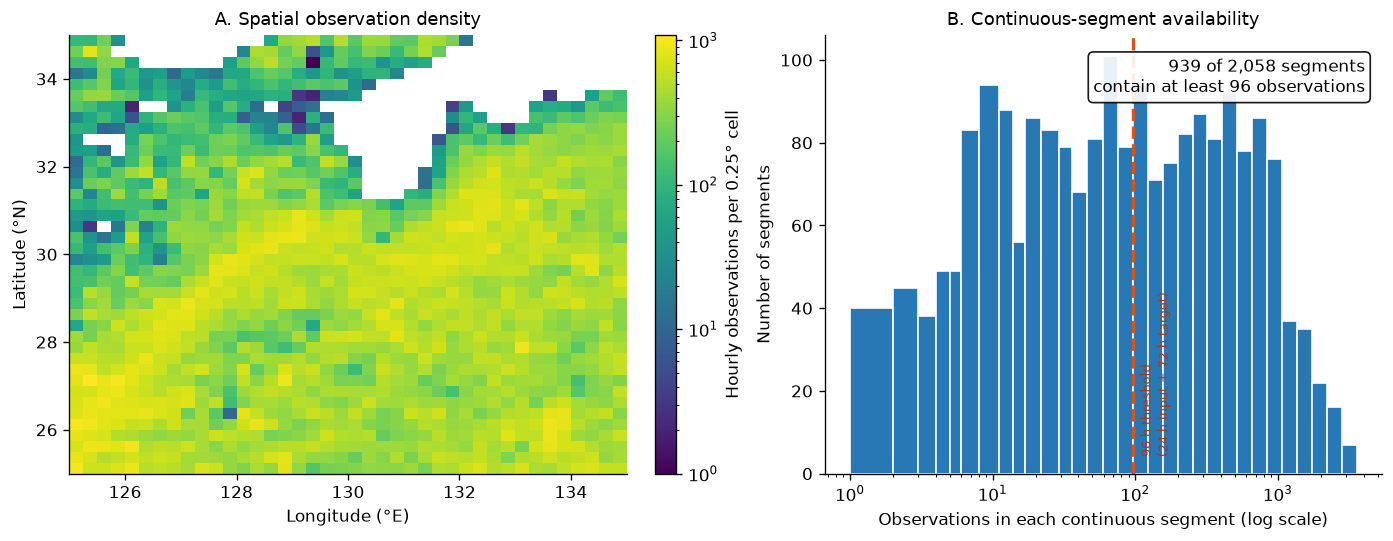

PosixPath('/Users/roger/Documents/data3001-project/final_submission/figures/report/RQ1/figure01_regionA_density_segments.png')

In [2]:
observations = pd.read_parquet(SUBMISSION / "data" / "processed" / "region_A_observations.parquet")
segments = pd.read_parquet(SUBMISSION / "data" / "processed" / "region_A_segments.parquet")

lon_edges = np.arange(125, 135.25, 0.25)
lat_edges = np.arange(25, 35.25, 0.25)
density, _, _ = np.histogram2d(
    observations["longitude"], observations["latitude"], bins=[lon_edges, lat_edges]
)
density = np.ma.masked_where(density.T == 0, density.T)

lengths = segments["n_observations"].clip(lower=1)
maximum = max(int(lengths.max()), 96)
bins = np.unique(np.logspace(0, np.log10(maximum + 1), 35).astype(int))
if bins[-1] <= maximum:
    bins = np.append(bins, maximum + 1)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.4), constrained_layout=True)
mesh = axes[0].pcolormesh(
    lon_edges, lat_edges, density, shading="auto", cmap="viridis",
    norm=LogNorm(vmin=1, vmax=float(density.max())),
)
fig.colorbar(mesh, ax=axes[0], label="Hourly observations per 0.25° cell")
axes[0].set(
    xlim=(125, 135), ylim=(25, 35), xlabel="Longitude (°E)", ylabel="Latitude (°N)",
    title="A. Spatial observation density",
)

axes[1].hist(lengths, bins=bins, color="#2878B5", edgecolor="white")
axes[1].axvline(96, color="#D95319", linestyle="--", linewidth=2)
axes[1].set_xscale("log")
axes[1].set(
    xlabel="Observations in each continuous segment (log scale)",
    ylabel="Number of segments", title="B. Continuous-segment availability",
)
eligible = int(segments["eligible_24_to_72"].sum())
axes[1].text(
    0.97, 0.95, f"{eligible:,} of {len(segments):,} segments\ncontain at least 96 observations",
    transform=axes[1].transAxes, ha="right", va="top",
    bbox={"boxstyle": "round", "facecolor": "white", "alpha": 0.9},
)
axes[1].text(105, 4, "96 h threshold\n(24 h input + 72 h target)", rotation=90,
             ha="left", va="bottom", color="#A13C13", fontsize=8)
finish_figure(fig, "figure01_regionA_density_segments.png")


## Forecasting methods and RQ1


### Figure 2 — Training-only spatial mean-flow field

Arrow direction gives local mean velocity; colour gives current speed. The field is estimated only from training observations.


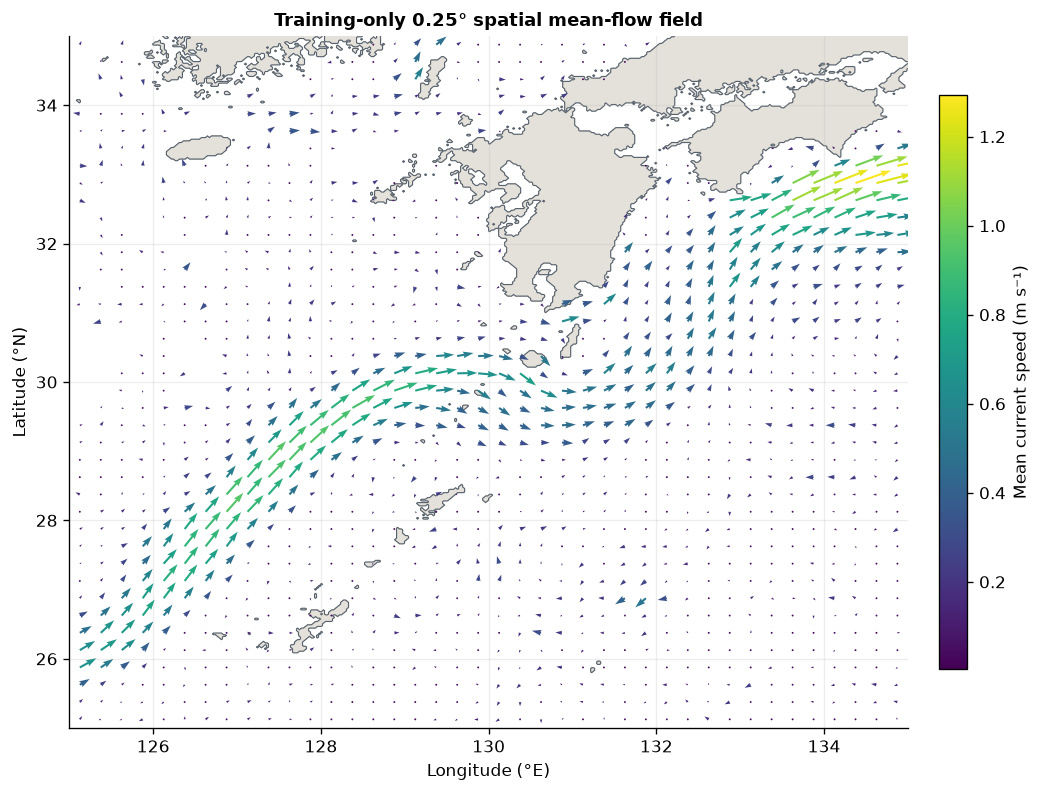

PosixPath('/Users/roger/Documents/data3001-project/final_submission/figures/report/RQ1/figure02_spatial_mean_flow.png')

In [3]:
flow = pd.read_csv(RQ1_OUTPUT / "zh" / "spatial_mean_flow_grid.csv")

fig, ax = plt.subplots(figsize=(9.3, 6.7))
draw_land(ax)
quiver = ax.quiver(
    flow["center_longitude"], flow["center_latitude"],
    flow["mean_ve"], flow["mean_vn"], flow["mean_speed"],
    cmap="viridis", angles="xy", scale_units="xy", scale=2.8,
    width=0.0025, headwidth=3.2, zorder=2,
)
ax.set(xlim=(125, 135), ylim=(25, 35), xlabel="Longitude (°E)", ylabel="Latitude (°N)")
ax.set_title("Training-only 0.25° spatial mean-flow field", weight="bold")
ax.grid(alpha=0.22)
cbar = fig.colorbar(quiver, ax=ax, pad=0.03, shrink=0.83)
cbar.set_label("Mean current speed (m s⁻¹)")
fig.tight_layout()
finish_figure(fig, "figure02_spatial_mean_flow.png")


### Figure 3 — Test-set trajectory-separation RMSE over lead time

Two physical baselines and six retained point models are compared on the same 757 held-out cases.


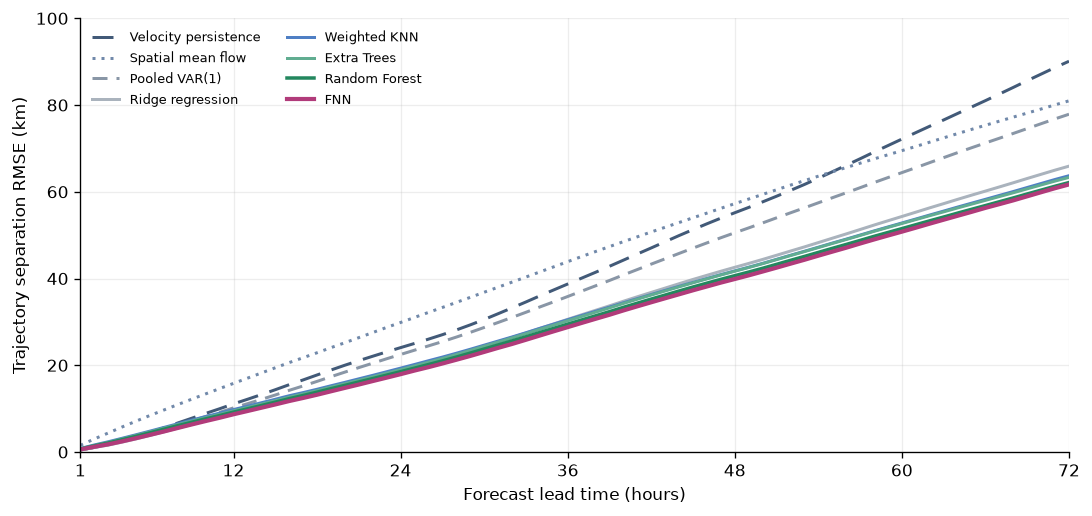

PosixPath('/Users/roger/Documents/data3001-project/final_submission/figures/report/RQ1/figure03_rmse_over_lead_time.png')

In [4]:
lead_files = {
    "Velocity persistence": RQ1_OUTPUT / "en" / "velocity_persistence_lead_metrics.csv",
    "Spatial mean flow": RQ1_OUTPUT / "en" / "spatial_mean_flow_lead_metrics.csv",
    "Pooled VAR(1)": RQ1_OUTPUT / "en" / "var1_lead_metrics.csv",
    "Ridge regression": RQ1_OUTPUT / "en" / "ridge_lead_metrics.csv",
    "Weighted KNN": RQ1_OUTPUT / "zh" / "optimised_knn_lead_metrics.csv",
    "Extra Trees": RQ1_OUTPUT / "zh" / "extra_trees_lead_metrics.csv",
    "Random Forest": RQ1_OUTPUT / "zh" / "random_forest_lead_metrics.csv",
    "FNN": RQ1_OUTPUT / "zh" / "optimised_fnn_lead_metrics.csv",
}
styles = {
    "Velocity persistence": ("#425a78", (0, (7, 4)), 1.8),
    "Spatial mean flow": ("#7189aa", (0, (1, 2)), 1.8),
    "Pooled VAR(1)": ("#8996a6", (0, (5, 3)), 1.8),
    "Ridge regression": ("#aab3bd", "-", 1.8),
    "Weighted KNN": ("#4f7fc4", "-", 1.8),
    "Extra Trees": ("#61ad91", "-", 1.8),
    "Random Forest": ("#23875e", "-", 2.1),
    "FNN": ("#b13b7a", "-", 2.5),
}

fig, ax = plt.subplots(figsize=(9.2, 4.4))
for model, path in lead_files.items():
    data = pd.read_csv(path)
    color, linestyle, width = styles[model]
    ax.plot(data["lead_time_hours"], data["rmse_km"], label=model,
            color=color, linestyle=linestyle, linewidth=width)
ax.set(xlim=(1, 72), ylim=(0, 100), xlabel="Forecast lead time (hours)",
       ylabel="Trajectory separation RMSE (km)")
ax.set_xticks([1, 12, 24, 36, 48, 60, 72])
ax.grid(alpha=0.22)
ax.legend(ncol=2, frameon=False, loc="upper left")
fig.tight_layout()
finish_figure(fig, "figure03_rmse_over_lead_time.png")


### Figure 4 — Held-out 72-hour RMSE ranking

All values use the same 757 test cases; lower is better.


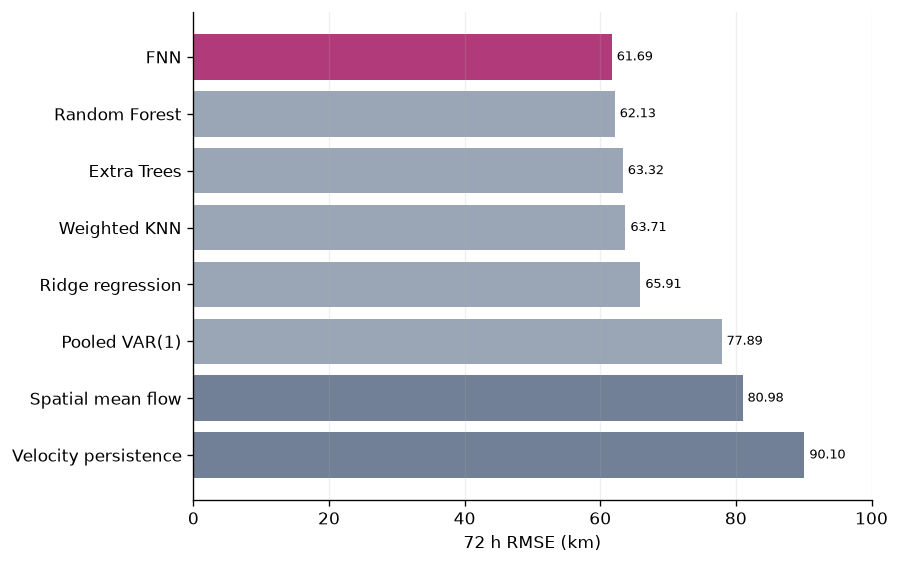

PosixPath('/Users/roger/Documents/data3001-project/final_submission/figures/report/RQ1/figure04_rmse_ranking.png')

In [5]:
comparison = pd.read_csv(RQ1_OUTPUT / "zh" / "complete_rq1_heldout_comparison_with_ite.csv")
selection = {
    "Velocity persistence": "Velocity persistence",
    "Spatial mean flow": "Spatial mean flow",
    "Pooled VAR(1)": "Pooled VAR(1)",
    "Ridge regression": "Ridge",
    "Weighted KNN": "Optimised KNN",
    "Extra Trees": "Extra Trees",
    "Random Forest": "Original Random Forest",
    "FNN": "Optimised FNN",
}
ranking = pd.concat([
    comparison.loc[comparison["model"].eq(source)].assign(display_model=label)
    for label, source in selection.items()
], ignore_index=True).sort_values("rmse_72h_km", ascending=False)

colors = ["#b13b7a" if m == "FNN" else "#718096" if m in {"Velocity persistence", "Spatial mean flow"}
          else "#9aa6b5" for m in ranking["display_model"]]
fig, ax = plt.subplots(figsize=(7.6, 4.8))
bars = ax.barh(ranking["display_model"], ranking["rmse_72h_km"], color=colors)
ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
ax.set(xlabel="72 h RMSE (km)", xlim=(0, 100))
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
finish_figure(fig, "figure04_rmse_ranking.png")


### Figure 5 — Complementary 72-hour endpoint and trajectory summaries

Models are ordered independently from lowest to highest in each panel. The selected FNN is highlighted; median endpoint error and median ITE are complementary to RMSE.


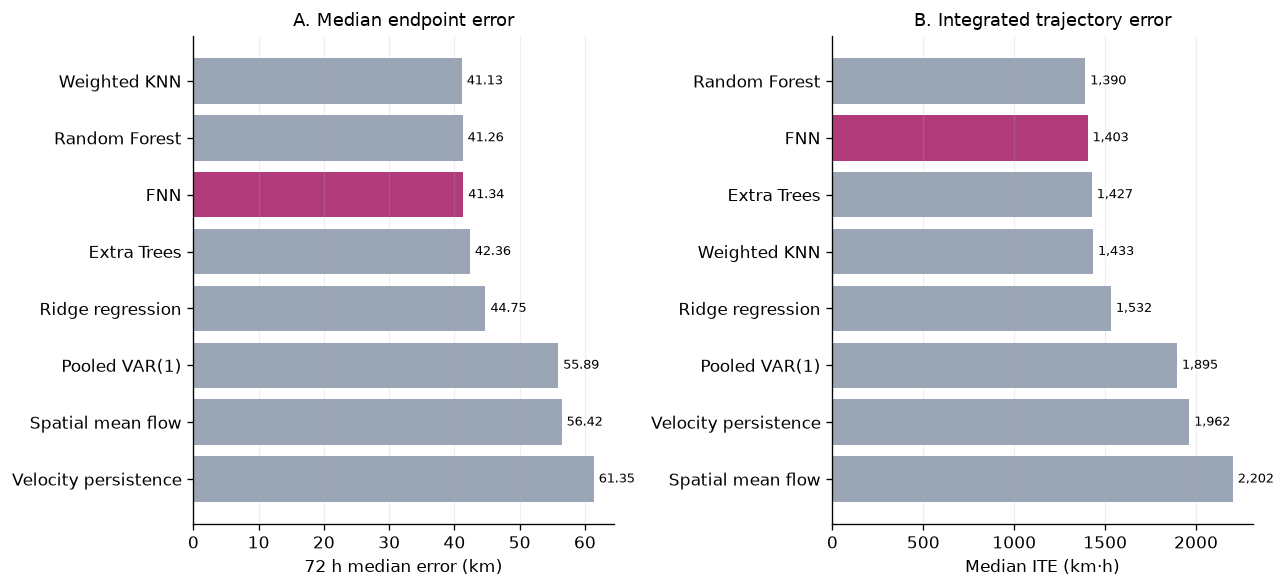

PosixPath('/Users/roger/Documents/data3001-project/final_submission/figures/report/RQ1/figure05_median_and_ite.png')

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10.8, 5.0))
for ax, metric, title, xlabel in [
    (axes[0], "median_72h_km", "A. Median endpoint error", "72 h median error (km)"),
    (axes[1], "median_ite_km_h", "B. Integrated trajectory error", "Median ITE (km·h)"),
]:
    ordered = ranking.sort_values(metric, ascending=False)
    panel_colors = ["#b13b7a" if m == "FNN" else "#9aa6b5" for m in ordered["display_model"]]
    bars = ax.barh(ordered["display_model"], ordered[metric], color=panel_colors)
    labels = [f"{v:.2f}" if metric == "median_72h_km" else f"{v:,.0f}" for v in ordered[metric]]
    ax.bar_label(bars, labels=labels, padding=3, fontsize=8)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
finish_figure(fig, "figure05_median_and_ite.png")


### Figure 6 — Paired drifter-clustered bootstrap contrasts

Negative RMSE differences favour the first-named model. The first two contrasts compare FNN with the physical baselines; the third checks whether Random Forest and FNN differ beyond sampling noise.


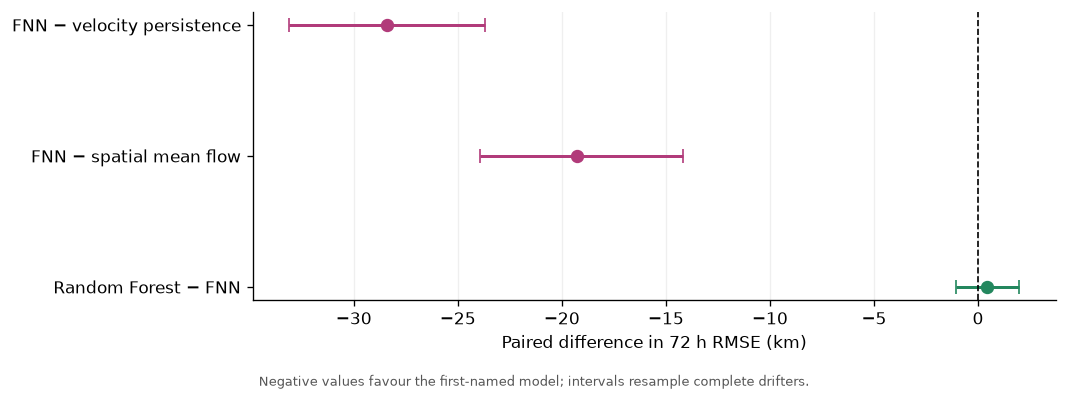

PosixPath('/Users/roger/Documents/data3001-project/final_submission/figures/report/RQ1/figure06_paired_bootstrap.png')

In [7]:
baseline_bootstrap = pd.read_csv(
    RQ1_OUTPUT / "zh" / "champion_models_bootstrap_vs_baselines.csv"
)
baseline_bootstrap = baseline_bootstrap.loc[
    baseline_bootstrap["model"].eq("Optimised FNN")
].copy()
baseline_bootstrap["label"] = baseline_bootstrap["baseline"].replace({
    "Velocity persistence": "FNN − velocity persistence",
    "Spatial mean flow": "FNN − spatial mean flow",
})

# Reproduce the report's FNN–Random Forest paired contrast by resampling
# complete test-drifter identities (5,000 replicates; fixed seed 3001).
fnn_cases = (
    pd.read_csv(RQ1_OUTPUT / "zh" / "optimised_fnn_test_case_metrics.csv")
    .rename(columns={"drifter_id": "ID", "error_72h_km": "fnn_error_km"})
    [["forecast_case_id", "ID", "fnn_error_km"]]
)
rf_cases = (
    pd.read_csv(RQ1_OUTPUT / "zh" / "random_forest_test_case_metrics.csv")
    .rename(columns={"final_72h_error_km": "rf_error_km"})
    [["forecast_case_id", "ID", "rf_error_km"]]
)
paired = fnn_cases.merge(rf_cases, on=["forecast_case_id", "ID"], validate="one_to_one")
cluster_totals = (
    paired.assign(fnn_sq=paired["fnn_error_km"] ** 2, rf_sq=paired["rf_error_km"] ** 2)
    .groupby("ID", as_index=False)
    .agg(n_cases=("forecast_case_id", "size"), fnn_sq=("fnn_sq", "sum"), rf_sq=("rf_sq", "sum"))
)
cluster_array = cluster_totals[["n_cases", "fnn_sq", "rf_sq"]].to_numpy(float)
rng = np.random.default_rng(3001)
sampled = cluster_array[
    rng.integers(0, len(cluster_array), size=(5000, len(cluster_array)))
].sum(axis=1)
fnn_minus_rf = np.sqrt(sampled[:, 1] / sampled[:, 0]) - np.sqrt(sampled[:, 2] / sampled[:, 0])
point_fnn_minus_rf = np.sqrt(np.mean(paired["fnn_error_km"] ** 2)) - np.sqrt(np.mean(paired["rf_error_km"] ** 2))
ci_low, ci_high = np.quantile(fnn_minus_rf, [0.025, 0.975])

rf_contrast = pd.DataFrame([{
    "label": "Random Forest − FNN",
    "rmse_difference_km": -point_fnn_minus_rf,
    "ci_2.5_km": -ci_high,
    "ci_97.5_km": -ci_low,
}])
contrasts = pd.concat([
    baseline_bootstrap[["label", "rmse_difference_km", "ci_2.5_km", "ci_97.5_km"]],
    rf_contrast,
], ignore_index=True)

y = np.arange(len(contrasts) - 1, -1, -1)
x = contrasts["rmse_difference_km"].to_numpy()
xerr = np.vstack([
    x - contrasts["ci_2.5_km"].to_numpy(),
    contrasts["ci_97.5_km"].to_numpy() - x,
])
colors = ["#b13b7a", "#b13b7a", "#23875e"]
fig, ax = plt.subplots(figsize=(9.0, 3.3))
for row, yi in enumerate(y):
    ax.errorbar(
        x[row], yi, xerr=xerr[:, row:row + 1], fmt="o",
        color=colors[row], ecolor=colors[row], capsize=4,
        markersize=7, linewidth=1.8,
    )
ax.axvline(0, color="black", linestyle="--", linewidth=1)
ax.set_yticks(y, contrasts["label"])
ax.set_xlabel("Paired difference in 72 h RMSE (km)")
ax.grid(axis="x", alpha=0.2)
fig.text(
    0.5, 0.01,
    "Negative values favour the first-named model; intervals resample complete drifters.",
    ha="center", fontsize=8, color="#555555",
)
fig.tight_layout(rect=(0, 0.05, 1, 1))
finish_figure(fig, "figure06_paired_bootstrap.png")


## RQ2 — Regional predictability


### Figure 7 — Kuroshio Core components and mean GLORYS current direction

The cyan regions are the two connected high-current components retained as the Kuroshio Core; arrows show the 1994–2022 mean surface-current direction.


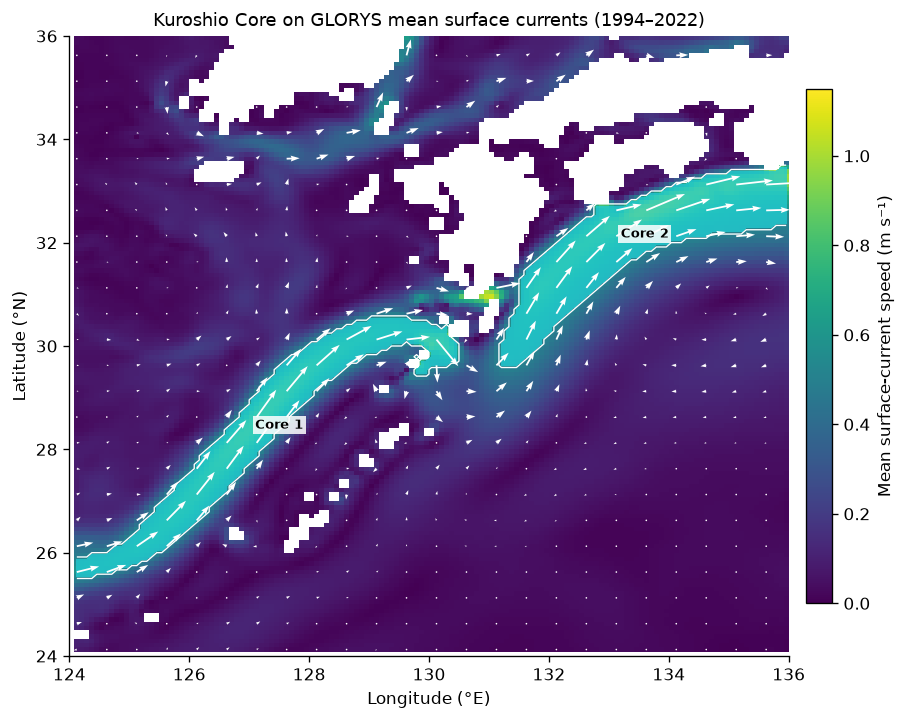

PosixPath('/Users/roger/Documents/data3001-project/final_submission/figures/report/RQ2/figure07_kuroshio_core_glorys.png')

In [8]:
clim = xr.open_dataset(RQ2 / "data" / "glorys_climatology_1994_2022.nc")
components = xr.open_dataset(RQ2 / "data" / "current_components_0p5.nc")
lon = clim["longitude"].values
lat = clim["latitude"].values
u = clim["u_mean"].values
v = clim["v_mean"].values
speed = clim["mean_vector_speed"].values
component_id = components["component_id"].values
core_mask = np.isin(component_id, [1, 2])

fig, ax = plt.subplots(figsize=(8.0, 6.1))
mesh = ax.pcolormesh(lon, lat, speed, cmap="viridis", shading="auto", vmin=0, vmax=1.15)
ax.contourf(lon, lat, np.where(core_mask, 1.0, np.nan), levels=[0.5, 1.5],
            colors=["#22cbd2"], alpha=0.78)
ax.contour(lon, lat, core_mask.astype(float), levels=[0.5], colors="white", linewidths=0.8)
step = 6
ax.quiver(lon[::step], lat[::step], u[::step, ::step], v[::step, ::step],
          color="white", angles="xy", scale_units="xy", scale=1.5,
          width=0.0025, headwidth=3.3)
ax.text(127.1, 28.4, "Core 1", fontsize=8, weight="bold",
        bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none", "pad": 1.5})
ax.text(133.2, 32.1, "Core 2", fontsize=8, weight="bold",
        bbox={"facecolor": "white", "alpha": 0.85, "edgecolor": "none", "pad": 1.5})
ax.set(xlim=(124, 136), ylim=(24, 36), xlabel="Longitude (°E)", ylabel="Latitude (°N)")
ax.set_title("Kuroshio Core on GLORYS mean surface currents (1994–2022)")
cbar = fig.colorbar(mesh, ax=ax, pad=0.02, shrink=0.83)
cbar.set_label("Mean surface-current speed (m s⁻¹)")
fig.tight_layout()
finish_figure(fig, "figure07_kuroshio_core_glorys.png")


### Figure 8 — Spatial distribution of held-out test cases by ocean regime

The plotted points are forecast-case origins; counts correspond to the four regime assignments used in the regional evaluation. The figure shows test origins rather than a complete raster of regime boundaries.


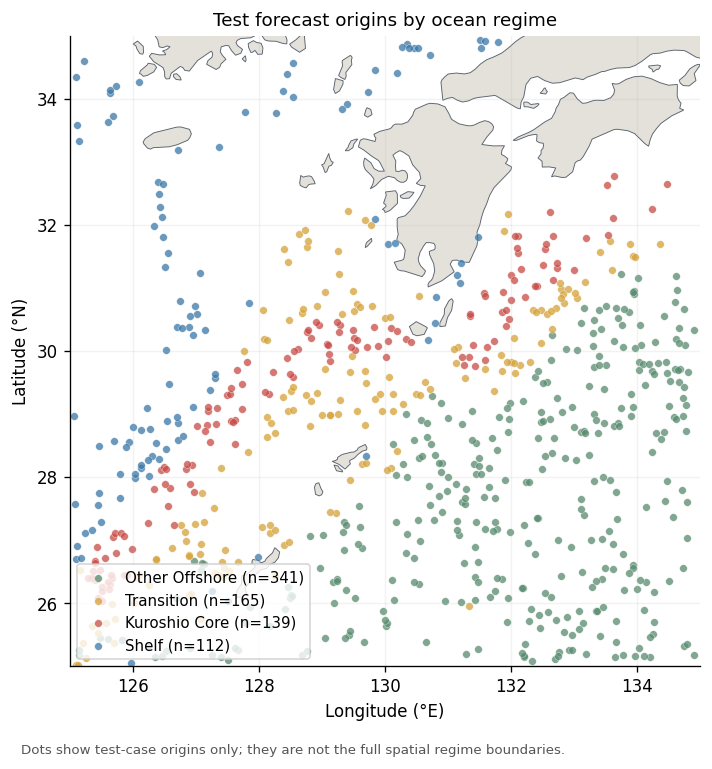

PosixPath('/Users/roger/Documents/data3001-project/final_submission/figures/report/RQ2/figure08_test_origins_by_regime.png')

In [2]:
regimes = pd.read_csv(RQ2 / "data" / "forecast_case_regimes.csv")
test_regimes = regimes.loc[regimes["partition"].eq("test")].copy()
regime_order = ["Shelf", "Kuroshio Core", "Transition", "Other Offshore"]
regime_colors = {
    "Shelf": "#3C78A8", "Kuroshio Core": "#C84C47",
    "Transition": "#D6A33A", "Other Offshore": "#598C70",
}

fig, ax = plt.subplots(figsize=(8.2, 6.4))
draw_land(ax)
for regime in regime_order[::-1]:
    part = test_regimes.loc[test_regimes["regime"].eq(regime)]
    ax.scatter(
        part["origin_longitude"], part["origin_latitude"], s=21,
        color=regime_colors[regime], edgecolor="white", linewidth=0.25,
        alpha=0.76, label=f"{regime} (n={len(part)})",
    )
ax.set(
    xlim=(125, 135), ylim=(25, 35),
    xlabel="Longitude (°E)", ylabel="Latitude (°N)",
    title="Test forecast origins by ocean regime",
)
ax.set_aspect("equal", adjustable="box")
ax.grid(alpha=0.16)
ax.legend(loc="lower left", frameon=True, fontsize=9)
fig.text(
    0.13, 0.01,
    "Dots show test-case origins only; they are not the full spatial regime boundaries.",
    fontsize=8, color="#555555",
)
fig.tight_layout(rect=(0, 0.03, 1, 1))
finish_figure(fig, "figure08_test_origins_by_regime.png")


### Figure 9 — Regional 72-hour errors for eight globally trained models

Median endpoint error and RMSE are shown for Shelf, Kuroshio Core, Transition and Other Offshore test cases. The figure uses the exact final model versions reported in RQ1: optimised FNN, optimised weighted KNN, original Random Forest and original Extra Trees, alongside the four fixed reference models.


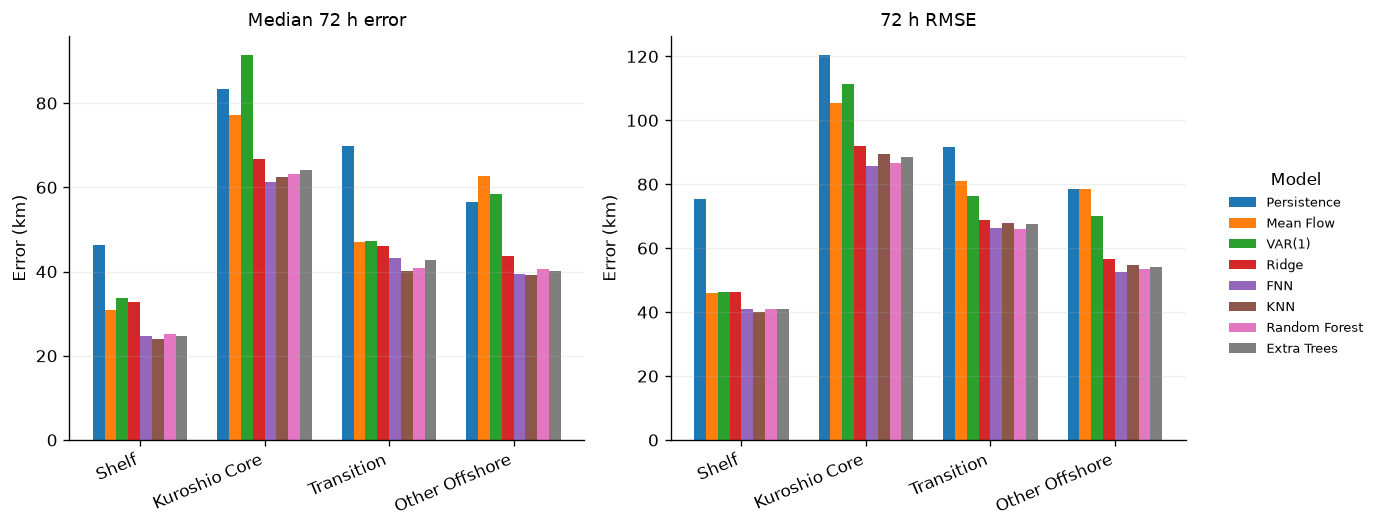

PosixPath('/Users/roger/Documents/data3001-project/final_submission/figures/report/RQ2/figure09_models_by_regime.png')

In [10]:
case_labels = test_regimes[["forecast_case_id", "regime"]].drop_duplicates()
final_model_files = {
    "Persistence": (RQ1_OUTPUT / "en" / "velocity_persistence_test_case_metrics.csv", "final_72h_error_km"),
    "Mean Flow": (RQ1_OUTPUT / "en" / "spatial_mean_flow_test_case_metrics.csv", "final_72h_error_km"),
    "VAR(1)": (RQ1_OUTPUT / "en" / "var1_test_case_metrics.csv", "final_72h_error_km"),
    "Ridge": (RQ1_OUTPUT / "en" / "ridge_test_case_metrics.csv", "final_72h_error_km"),
    "KNN": (RQ1_OUTPUT / "zh" / "optimised_knn_test_case_metrics.csv", "error_72h_km"),
    "FNN": (RQ1_OUTPUT / "zh" / "optimised_fnn_test_case_metrics.csv", "error_72h_km"),
    "Random Forest": (RQ1_OUTPUT / "zh" / "random_forest_test_case_metrics.csv", "final_72h_error_km"),
    "Extra Trees": (RQ1_OUTPUT / "zh" / "extra_trees_test_case_metrics.csv", "final_72h_error_km"),
}
model_frames = []
for model, (path, error_column) in final_model_files.items():
    values = (
        pd.read_csv(path)[["forecast_case_id", error_column]]
        .rename(columns={error_column: "final_72h_error_km"})
        .merge(case_labels, on="forecast_case_id", how="inner", validate="one_to_one")
    )
    values["model"] = model
    model_frames.append(values)

plot_errors = pd.concat(model_frames, ignore_index=True)
regional_summary = (
    plot_errors.groupby(["regime", "model"], observed=True)["final_72h_error_km"]
    .agg(median_72h_km="median", rmse_72h_km=lambda values: np.sqrt(np.mean(np.square(values))))
    .reset_index()
)
model_order = ["Persistence", "Mean Flow", "VAR(1)", "Ridge", "FNN", "KNN", "Random Forest", "Extra Trees"]
regime_order_plot = ["Shelf", "Kuroshio Core", "Transition", "Other Offshore"]
colors = dict(zip(model_order, plt.get_cmap("tab10").colors[:len(model_order)]))
x = np.arange(len(regime_order_plot))
bar_width = 0.095

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.5), sharex=True)
for ax, metric, title in zip(
    axes, ["median_72h_km", "rmse_72h_km"],
    ["Median 72 h error", "72 h RMSE"],
):
    for index, model in enumerate(model_order):
        values = (
            regional_summary.loc[regional_summary["model"].eq(model)]
            .set_index("regime").reindex(regime_order_plot)[metric]
        )
        offset = (index - (len(model_order) - 1) / 2) * bar_width
        ax.bar(x + offset, values, width=bar_width, color=colors[model], label=model)
    ax.set_title(title)
    ax.set_ylabel("Error (km)")
    ax.set_xticks(x, regime_order_plot, rotation=23, ha="right")
    ax.grid(axis="y", alpha=0.2)
handles, legend_labels = axes[1].get_legend_handles_labels()
fig.legend(
    handles, legend_labels, title="Model", loc="center left",
    bbox_to_anchor=(0.91, 0.5), frameon=False,
)
fig.tight_layout(rect=(0, 0, 0.90, 1))
finish_figure(fig, "figure09_models_by_regime.png")


### Figure 10 — FNN Core–Shelf error differences under alternative regime definitions

The sensitivity grid uses the optimised FNN carried forward from RQ1 and varies the GLORYS speed threshold and transition-buffer width.


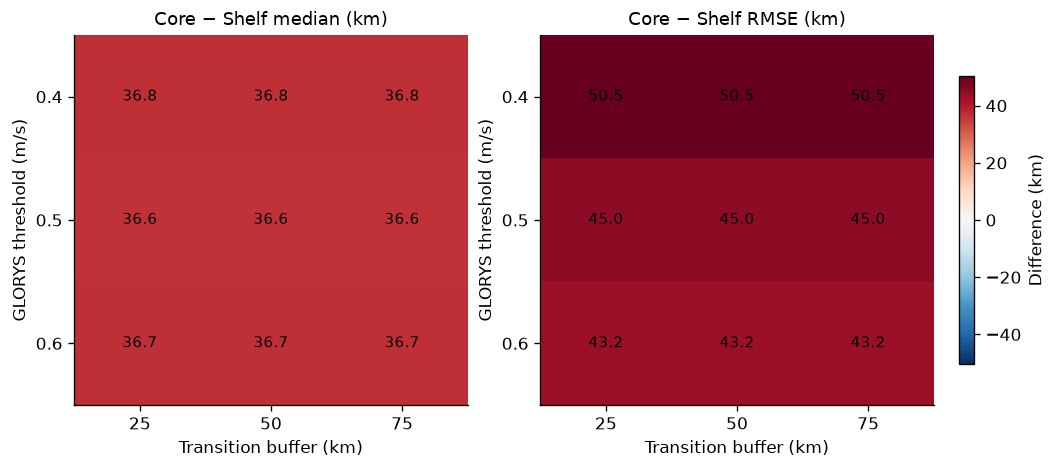

PosixPath('/Users/roger/Documents/data3001-project/final_submission/figures/report/RQ2/figure10_fnn_core_shelf_sensitivity.png')

In [11]:
sensitivity = pd.read_csv(
    RQ2 / "results" / "optimised_fnn_analysis" / "sensitivity_optimised_fnn.csv"
)
median_grid = (
    sensitivity.loc[sensitivity["metric"].eq("median")]
    .pivot(index="threshold_m_s", columns="buffer_km", values="core_minus_shelf_km")
    .sort_index()
)
rmse_grid = (
    sensitivity.loc[sensitivity["metric"].eq("rmse")]
    .pivot(index="threshold_m_s", columns="buffer_km", values="core_minus_shelf_km")
    .sort_index()
)
limit = float(np.nanmax(np.abs([median_grid.values, rmse_grid.values])))
norm = TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit)
fig, axes = plt.subplots(1, 2, figsize=(8.7, 3.8), constrained_layout=True)
for ax, grid, title in zip(
    axes,
    [median_grid, rmse_grid],
    ["Core − Shelf median (km)", "Core − Shelf RMSE (km)"],
):
    image = ax.imshow(grid.values, cmap="RdBu_r", norm=norm, aspect="auto")
    ax.set_title(title)
    ax.set_xlabel("Transition buffer (km)")
    ax.set_ylabel("GLORYS threshold (m/s)")
    ax.set_xticks(range(len(grid.columns)), [int(value) for value in grid.columns])
    ax.set_yticks(range(len(grid.index)), [f"{value:.1f}" for value in grid.index])
    for row in range(grid.shape[0]):
        for column in range(grid.shape[1]):
            ax.text(
                column, row, f"{grid.iloc[row, column]:.1f}",
                ha="center", va="center", fontsize=9,
            )
cbar = fig.colorbar(image, ax=axes, shrink=0.78, pad=0.03)
cbar.set_label("Difference (km)")
finish_figure(fig, "figure10_fnn_core_shelf_sensitivity.png")


### Figure 11 — Global and Core-only model RMSE on Kuroshio Core test cases

Five model families are evaluated on the same 139 Core test cases from 45 drifters.


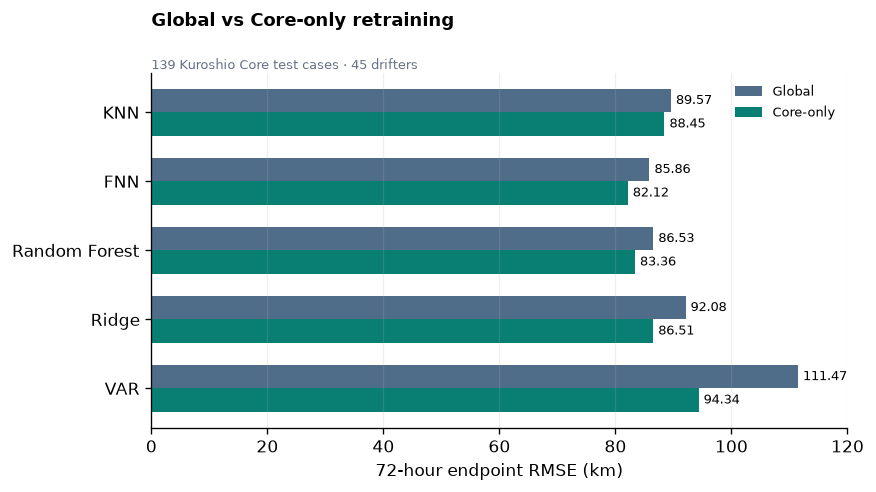

PosixPath('/Users/roger/Documents/data3001-project/final_submission/figures/report/RQ2/figure11_global_vs_core_only_rmse.png')

In [12]:
retraining = pd.read_csv(
    RQ2 / "results" / "optimised_fnn_analysis" / "regional_retraining_five_models_summary.csv"
)
model_order_retraining = ["KNN", "FNN", "Random Forest", "Ridge", "VAR"]
retraining = retraining.set_index("model").reindex(model_order_retraining).reset_index()
y = np.arange(len(retraining))
height = 0.34
fig, ax = plt.subplots(figsize=(7.4, 4.2))
global_bars = ax.barh(y - height / 2, retraining["global_rmse_km"], height=height,
                      color="#4f6d89", label="Global")
core_bars = ax.barh(y + height / 2, retraining["regional_rmse_km"], height=height,
                    color="#087f72", label="Core-only")
for bars in [global_bars, core_bars]:
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=8)
ax.set_yticks(y, retraining["model"])
ax.invert_yaxis()
ax.set(xlabel="72-hour endpoint RMSE (km)", xlim=(0, 120))
ax.set_title("Global vs Core-only retraining", loc="left", weight="bold", pad=28)
ax.text(0, 1.01, "139 Kuroshio Core test cases · 45 drifters",
        transform=ax.transAxes, fontsize=8, color="#667085")
ax.legend(frameon=False, loc="upper right")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
finish_figure(fig, "figure11_global_vs_core_only_rmse.png")


### Figure 12 — Percentage reduction in RMSE after Core-only retraining

Positive values indicate lower RMSE after the Core-only refit.


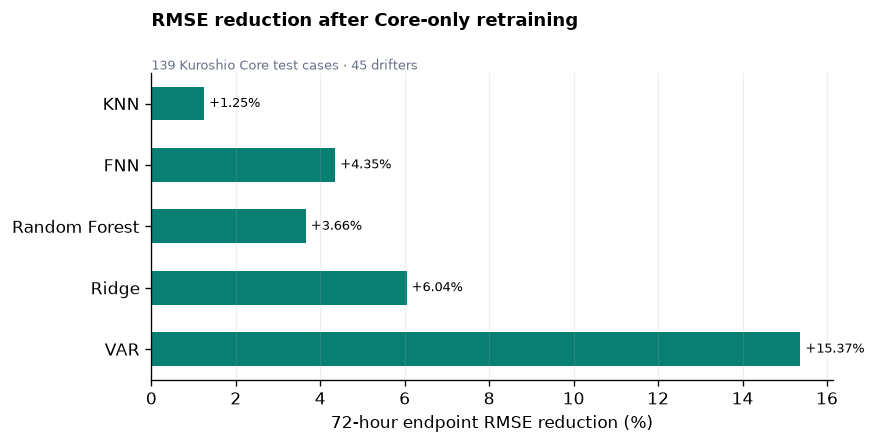

PosixPath('/Users/roger/Documents/data3001-project/final_submission/figures/report/RQ2/figure12_core_only_rmse_reduction.png')

In [13]:
fig, ax = plt.subplots(figsize=(7.4, 3.8))
bars = ax.barh(y, retraining["reduction_pct"], color="#087f72", height=0.55)
ax.bar_label(bars, labels=[f"+{value:.2f}%" for value in retraining["reduction_pct"]],
             padding=3, fontsize=8)
ax.set_yticks(y, retraining["model"])
ax.invert_yaxis()
ax.set_xlabel("72-hour endpoint RMSE reduction (%)")
ax.set_title("RMSE reduction after Core-only retraining", loc="left", weight="bold", pad=28)
ax.text(0, 1.01, "139 Kuroshio Core test cases · 45 drifters",
        transform=ax.transAxes, fontsize=8, color="#667085")
ax.grid(axis="x", alpha=0.2)
fig.tight_layout()
finish_figure(fig, "figure12_core_only_rmse_reduction.png")


## RQ3 — Conformal uncertainty calibration


### Figure 13 — Global 90% empirical coverage and calibrated radius over lead time

The dashed line marks the nominal coverage target.


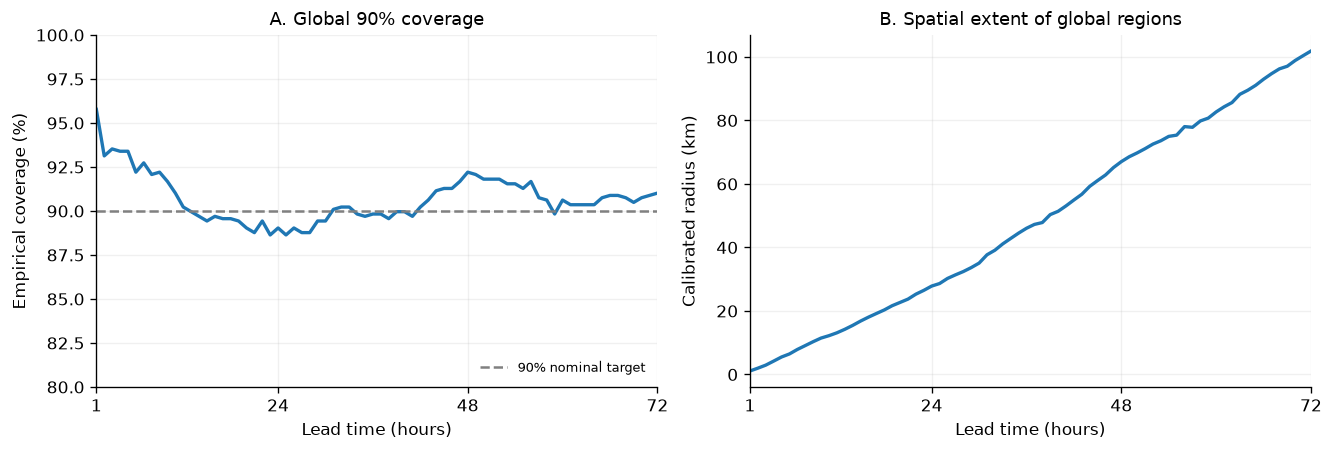

PosixPath('/Users/roger/Documents/data3001-project/final_submission/figures/report/RQ3/figure13_global_coverage_radius.png')

In [14]:
leads = pd.read_csv(RQ3_OUTPUT / "optimised_fnn_multi_nominal_by_lead.csv")
regime_conformal = pd.read_csv(RQ3_OUTPUT / "optimised_fnn_conformal_regime_summary.csv")
s = leads.loc[leads["nominal_coverage"].eq(0.9)].sort_values("lead_time_hours")
fig, axes = plt.subplots(1, 2, figsize=(11, 3.65), layout="constrained")
axes[0].plot(s["lead_time_hours"], 100 * s["empirical_coverage"], linewidth=2)
axes[0].axhline(90, linestyle="--", color="grey", label="90% nominal target")
axes[0].set(xlabel="Lead time (hours)", ylabel="Empirical coverage (%)",
            title="A. Global 90% coverage", xlim=(1, 72), ylim=(80, 100))
axes[0].legend(loc="lower right", frameon=False)
axes[1].plot(s["lead_time_hours"], s["radius_km"], linewidth=2)
axes[1].set(xlabel="Lead time (hours)", ylabel="Calibrated radius (km)",
            title="B. Spatial extent of global regions", xlim=(1, 72))
for ax in axes:
    ax.set_xticks([1, 24, 48, 72])
    ax.grid(alpha=0.18)
finish_figure(fig, "figure13_global_coverage_radius.png")


### Figure 14 — Global versus Mondrian empirical coverage by ocean regime

Coverage is evaluated at 72 hours for the 90% nominal target.


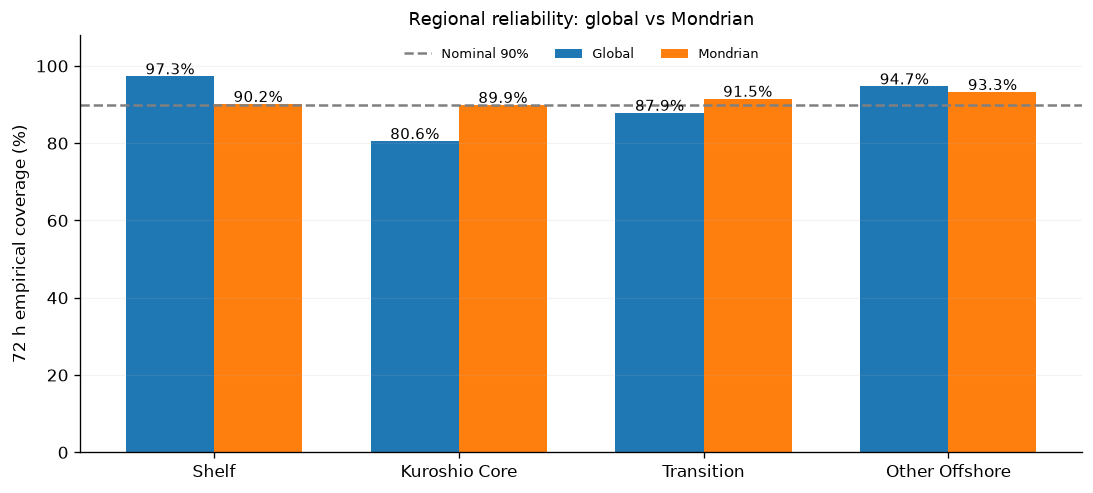

PosixPath('/Users/roger/Documents/data3001-project/final_submission/figures/report/RQ3/figure14_regime_coverage.png')

In [15]:
order = ["Shelf", "Kuroshio Core", "Transition", "Other Offshore"]
coverage = regime_conformal.pivot(index="regime", columns="method", values="coverage_72h").loc[order]
fig, ax = plt.subplots(figsize=(9, 4), layout="constrained")
x = np.arange(4)
width = 0.36
for offset, method in [(-width / 2, "Global"), (width / 2, "Mondrian")]:
    bars = ax.bar(x + offset, 100 * coverage[method], width, label=method)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.5,
                f"{bar.get_height():.1f}%", ha="center", fontsize=9)
ax.axhline(90, linestyle="--", color="grey", label="Nominal 90%")
ax.set(xticks=x, xticklabels=order, ylabel="72 h empirical coverage (%)",
       ylim=(0, 108), title="Regional reliability: global vs Mondrian")
ax.legend(ncol=3, frameon=False, loc="upper center")
ax.grid(axis="y", alpha=0.15)
finish_figure(fig, "figure14_regime_coverage.png")


### Figure 15 — Global and Mondrian radii and circular-area changes

The left panel compares 72-hour radii; the right panel shows the relative change in circular region area under Mondrian calibration.


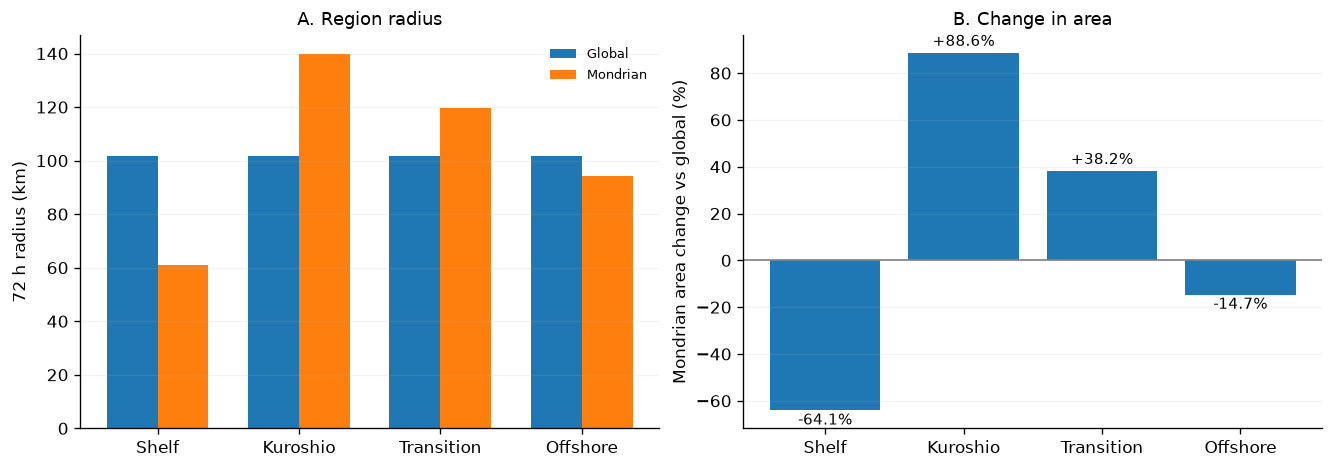

PosixPath('/Users/roger/Documents/data3001-project/final_submission/figures/report/RQ3/figure15_radius_area_tradeoff.png')

In [16]:
area = regime_conformal.pivot(index="regime", columns="method", values="area_72h_km2").loc[order]
radius = regime_conformal.pivot(index="regime", columns="method", values="radius_72h_km").loc[order]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
x = np.arange(4)
axes[0].bar(x - 0.18, radius["Global"], 0.36, label="Global")
axes[0].bar(x + 0.18, radius["Mondrian"], 0.36, label="Mondrian")
axes[0].set(xticks=x, xticklabels=["Shelf", "Kuroshio", "Transition", "Offshore"],
            ylabel="72 h radius (km)", title="A. Region radius")
axes[0].legend(frameon=False)
area_change = 100 * (area["Mondrian"] / area["Global"] - 1)
bars = axes[1].bar(x, area_change)
axes[1].axhline(0, color="grey", linewidth=1)
axes[1].set(xticks=x, xticklabels=["Shelf", "Kuroshio", "Transition", "Offshore"],
            ylabel="Mondrian area change vs global (%)", title="B. Change in area")
for bar, value in zip(bars, area_change):
    axes[1].text(bar.get_x() + bar.get_width() / 2, value + (3 if value >= 0 else -6),
                 f"{value:+.1f}%", ha="center", fontsize=9)
for ax in axes:
    ax.grid(axis="y", alpha=0.15)
finish_figure(fig, "figure15_radius_area_tradeoff.png")


### Figure 16 — Empirical versus nominal coverage across four regimes

Global and Mondrian calibration are compared at 80%, 90% and 95% nominal coverage; the dashed diagonal indicates ideal calibration.


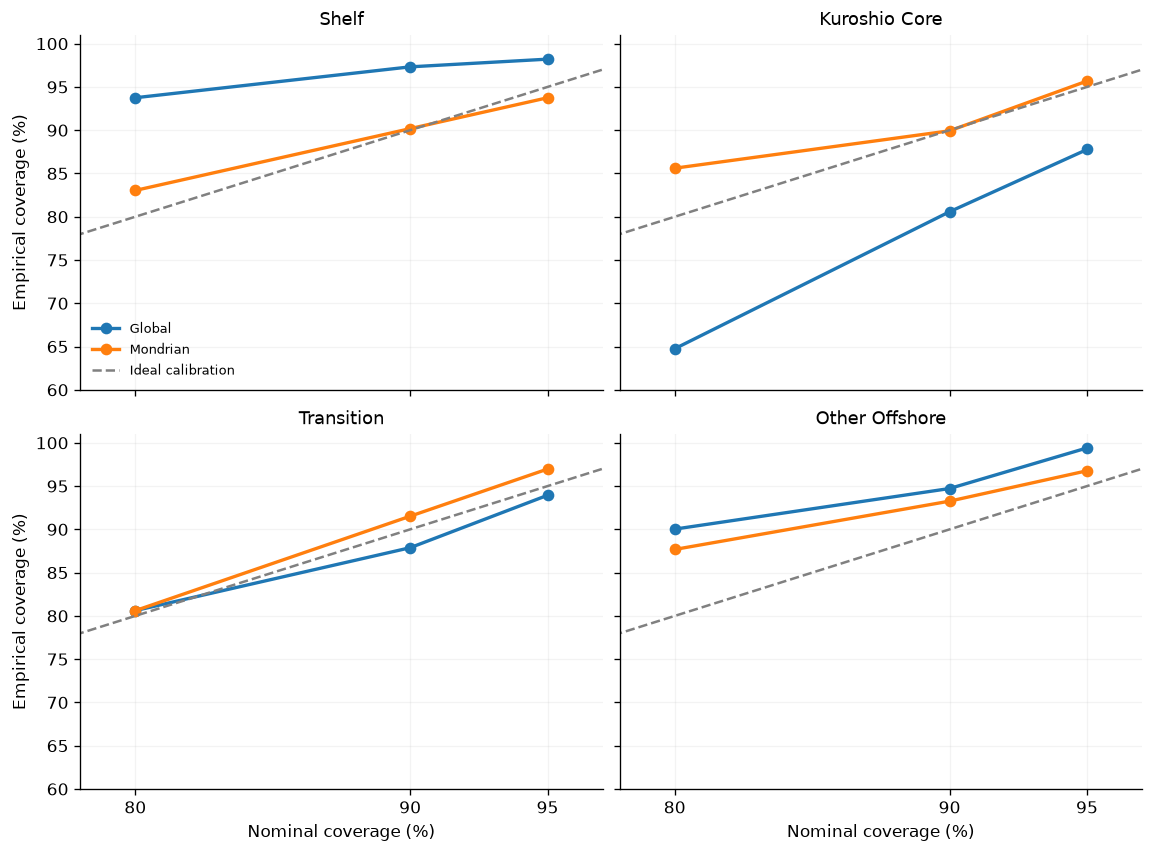

PosixPath('/Users/roger/Documents/data3001-project/final_submission/figures/report/RQ3/figure16_multinominal_coverage.png')

In [17]:
multi = pd.read_csv(RQ3_OUTPUT / "optimised_fnn_regime_multi_nominal_72h.csv")
fig, axes = plt.subplots(2, 2, figsize=(9.5, 7), layout="constrained", sharex=True, sharey=True)
for ax, regime in zip(axes.flat, order):
    for method in ["Global", "Mondrian"]:
        values = multi.loc[(multi["regime"].eq(regime)) & (multi["method"].eq(method))].sort_values("nominal_coverage")
        ax.plot(values["nominal_coverage"] * 100, values["empirical_coverage"] * 100,
                marker="o", linewidth=2, label=method)
    ax.plot([75, 100], [75, 100], "--", color="grey", label="Ideal calibration")
    ax.set(title=regime, xlim=(78, 97), ylim=(60, 101), xticks=[80, 90, 95])
    ax.grid(alpha=0.15)
for ax in axes[1, :]:
    ax.set_xlabel("Nominal coverage (%)")
for ax in axes[:, 0]:
    ax.set_ylabel("Empirical coverage (%)")
axes[0, 0].legend(fontsize=8, frameon=False)
finish_figure(fig, "figure16_multinominal_coverage.png")
